<a href="https://colab.research.google.com/github/vifirsanova/ML-2026-pt-2/blob/main/beginners/rnn_tutorial" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Классификация текстов с помощью RNN (PyTorch)

- загрузка и визуализация данных;
- токенизация и словарь;
- RNN-классификатор;
- обучение, кривые, матрица ошибок;
- задания с плейсхолдерами для изменения гиперпараметров.

## 1. Окружение

In [ ]:
!pip install -q datasets scikit-learn seaborn tqdm matplotlib

In [ ]:
import re
import random
import time
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import DataLoader
from torch.nn.utils.rnn import (
    pad_sequence,
    pack_padded_sequence
)

from datasets import load_dataset
from sklearn.metrics import confusion_matrix, classification_report
from tqdm import tqdm

In [ ]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    'cuda' if torch.cuda.is_available() else 'cpu'
)

print(f"Using device: {device}")

Using device: cuda


## 2. Загрузка данных

In [ ]:
dataset = load_dataset("fancyzhx/ag_news")

print(dataset)
print("\nПример:", dataset['train'][0])

README.md:   0%|          | 0.00/8.07k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 18.6MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.23MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/120000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/7600 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 120000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 7600
    })
})

Пример: {'text': "Wall St. Bears Claw Back Into the Black (Reuters) Reuters - Short-sellers, Wall Street's dwindling\\band of ultra-cynics, are seeing green again.", 'label': 2}


In [ ]:
train_data = list(zip(
    dataset['train']['label'],
    dataset['train']['text']
))

test_data = list(zip(
    dataset['test']['label'],
    dataset['test']['text']
))

print(f"Обучающих примеров: {len(train_data)}")
print(f"Тестовых примеров: {len(test_data)}")

print(
    f"\nРаспределение меток: "
    f"{Counter(label for label, _ in train_data)}"
)

Обучающих примеров: 120000
Тестовых примеров: 7600

Распределение меток: Counter({2: 30000, 3: 30000, 1: 30000, 0: 30000})


## 3. Визуализация данных

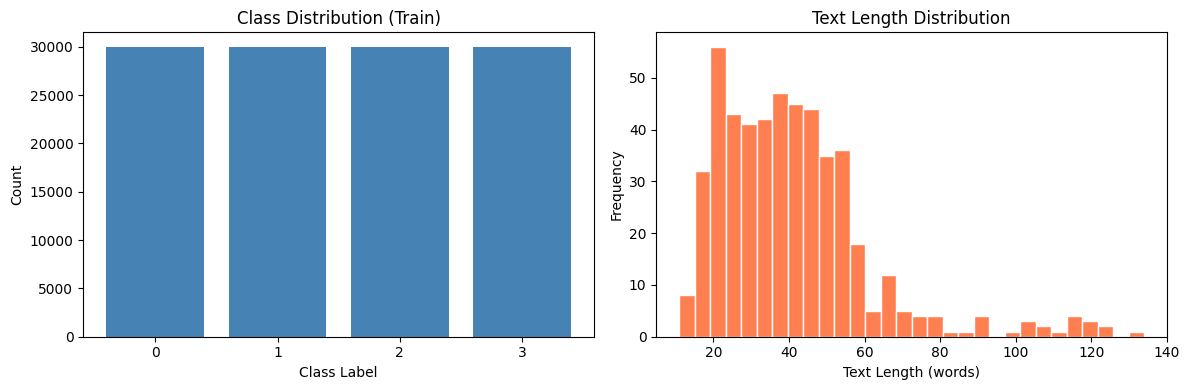

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

labels = [label for label, _ in train_data]
label_counts = Counter(labels)

axes[0].bar(
    label_counts.keys(),
    label_counts.values(),
    color='steelblue'
)

axes[0].set_xlabel('Class Label')
axes[0].set_ylabel('Count')
axes[0].set_title('Class Distribution (Train)')
axes[0].set_xticks([0, 1, 2, 3])

lengths = [
    len(text.split())
    for _, text in train_data[:500]
]

axes[1].hist(
    lengths,
    bins=30,
    color='coral',
    edgecolor='white'
)

axes[1].set_xlabel('Text Length (words)')
axes[1].set_ylabel('Frequency')
axes[1].set_title('Text Length Distribution')

plt.tight_layout()
plt.show()

In [ ]:
print("\n=== Примеры ===")

for i in range(3):
    label, text = train_data[i]
    print(f"[Label {label}] {text[:150]}...")


=== Примеры ===
[Label 2] Wall St. Bears Claw Back Into the Black (Reuters) Reuters - Short-sellers, Wall Street's dwindling\band of ultra-cynics, are seeing green again....
[Label 2] Carlyle Looks Toward Commercial Aerospace (Reuters) Reuters - Private investment firm Carlyle Group,\which has a reputation for making well-timed and ...
[Label 2] Oil and Economy Cloud Stocks' Outlook (Reuters) Reuters - Soaring crude prices plus worries\about the economy and the outlook for earnings are expecte...


## 4. Токенизация и словарь

In [ ]:
def tokenizer(text):
    """
    Простой токенизатор без torchtext.
    Приводит текст к нижнему регистру и отделяет пунктуацию.
    """
    return re.findall(
        r"\w+|[^\w\s]",
        text.lower()
    )


def yield_tokens(data):
    for _, text in data:
        yield tokenizer(text)

In [ ]:
def build_vocab_from_iterator(iterator, min_freq=1):
    counter = Counter()

    for tokens in iterator:
        counter.update(tokens)

    # Индексы специальных токенов:
    # <pad> = 0
    # <unk> = 1
    vocab = {
        '<pad>': 0,
        '<unk>': 1,
    }

    frequent_tokens = [
        token
        for token, frequency in counter.items()
        if frequency >= min_freq
        and token not in ('<pad>', '<unk>')
    ]

    # Сначала частые слова, затем алфавитный порядок
    frequent_tokens.sort(
        key=lambda token: (-counter[token], token)
    )

    vocab.update({
        token: index
        for index, token in enumerate(
            frequent_tokens,
            start=2
        )
    })

    return vocab

In [ ]:
# ============================================
# Задание 1: параметры построения словаря
# Попробуйте min_freq = 2 или 10. Как меняются размер словаря и качество модели?
# Почему редкие слова могут как помогать, так и мешать?
# ============================================
MIN_FREQ = 2  # <-- меняйте здесь

# Сначала строим словарь только из реальных токенов
vocab = build_vocab_from_iterator(
    yield_tokens(train_data),
    min_freq=MIN_FREQ
)

# Добавляем специальные токены вручную
# Порядок важен: <pad> должен быть первым (индекс 0), <unk> — вторым (индекс 1)

# Устанавливаем токен по умолчанию для неизвестных слов
PAD_IDX = vocab['<pad>']
UNK_IDX = vocab['<unk>']

print(f"Размер словаря: {len(vocab)}")
print(f"PAD_IDX = {PAD_IDX}, UNK_IDX = {UNK_IDX}")

Размер словаря: 44138
PAD_IDX = 0, UNK_IDX = 1


## 5. Предобработка и Dataset


In [ ]:
# ============================================
# Задание 2: длина последовательности (обрезка)
# Попробуйте MAX_LEN = 128, 256, 512. Как меняются скорость обучения и точность?
# Почему у RNN может не быть выигрыша от очень длинных последовательностей?
# ============================================
MAX_LEN = 256  # <-- меняйте здесь

In [ ]:
def text_pipeline(text):
    tokens = tokenizer(text)

    ids = [
        vocab.get(token, UNK_IDX)
        for token in tokens
    ]

    if len(ids) > MAX_LEN:
        ids = ids[:MAX_LEN]

    # На случай пустого текста
    if len(ids) == 0:
        ids = [UNK_IDX]

    return ids


def label_pipeline(label):
    return label

In [ ]:
class AGNewsDataset(torch.utils.data.Dataset):
    def __init__(
        self,
        data,
        text_pipeline,
        label_pipeline
    ):
        self.data = data
        self.text_pipeline = text_pipeline
        self.label_pipeline = label_pipeline

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        label, text = self.data[idx]

        ids = self.text_pipeline(text)

        return (
            torch.tensor(ids, dtype=torch.long),
            torch.tensor(
                self.label_pipeline(label),
                dtype=torch.long
            )
        )

In [ ]:
def collate_batch(batch):
    text_list, label_list = zip(*batch)

    lengths = torch.tensor(
        [len(text) for text in text_list],
        dtype=torch.long
    )

    padded = pad_sequence(
        text_list,
        batch_first=True,
        padding_value=PAD_IDX
    )

    labels = torch.stack(label_list)

    return padded, lengths, labels

In [ ]:
train_dataset = AGNewsDataset(
    train_data,
    text_pipeline,
    label_pipeline
)

test_dataset = AGNewsDataset(
    test_data,
    text_pipeline,
    label_pipeline
)

## 6. DataLoader

In [ ]:
# ============================================
# Задание 3: размер батча
# Попробуйте BATCH_SIZE = 32, 64, 128. Как это влияет на стабильность обучения и скорость?
# Документация: https://pytorch.org/docs/stable/data.html#torch.utils.data.DataLoader
# ============================================
BATCH_SIZE = 64  # <-- меняйте здесь

In [ ]:
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_batch,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_batch,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

print(
    f"Количество батчей в обучении: "
    f"{len(train_loader)}"
)

Количество батчей в обучении: 1875


In [ ]:
# Диагностика влияния MAX_LEN: берём один батч и смотрим форму
padded, lengths, labels = next(iter(train_loader))

print(f"MAX_LEN = {MAX_LEN}")
print(f"Форма батча padded: {padded.shape}")   # (batch_size, длина самого длинного текста в батче)
print(f"Ширина (число токенов на пример): {padded.shape[1]}")
print(f"Реальные длины текстов в батче: min={lengths.min().item()}, "
      f"max={lengths.max().item()}, mean={lengths.float().mean():.1f}")
print(f"Доля паддинга в батче: "
      f"{1 - lengths.sum().item() / (padded.shape[0] * padded.shape[1]):.1%}")

MAX_LEN = 256
Форма батча padded: torch.Size([64, 94])
Ширина (число токенов на пример): 94
Реальные длины текстов в батче: min=22, max=94, mean=45.9
Доля паддинга в батче: 51.1%


## 7. RNN-модель

In [ ]:
class RNNClassifier(nn.Module):
    def __init__(
        self,
        vocab_size,
        embed_dim,
        hidden_dim,
        num_classes,
        num_layers=1,
        dropout=0.2,
        bidirectional=False
    ):
        super().__init__()

        self.embedding = nn.Embedding(
            num_embeddings=vocab_size,
            embedding_dim=embed_dim,
            padding_idx=PAD_IDX
        )

        self.rnn = nn.RNN(
            input_size=embed_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0,
            bidirectional=bidirectional
        )

        rnn_output_dim = (
            hidden_dim * 2
            if bidirectional
            else hidden_dim
        )

        self.fc = nn.Linear(
            rnn_output_dim,
            num_classes
        )

        self.dropout = nn.Dropout(dropout)

    def forward(self, x, lengths):
        embedded = self.dropout(
            self.embedding(x)
        )

        packed = pack_padded_sequence(
            embedded,
            lengths.cpu(),
            batch_first=True,
            enforce_sorted=False
        )

        _, hidden = self.rnn(packed)

        if self.rnn.bidirectional:
            last_hidden = torch.cat(
                [hidden[-2], hidden[-1]],
                dim=1
            )
        else:
            last_hidden = hidden[-1]

        output = self.fc(
            self.dropout(last_hidden)
        )

        return output

In [ ]:
# ============================================
# Задание 4: гиперпараметры модели
# Попробуйте разные комбинации и посмотрите на точность на валидации:
#   EMBED_DIM: 64, 128, 256
#   HIDDEN_DIM: 64, 128, 256
#   NUM_LAYERS: 1, 2
#   BIDIRECTIONAL: True / False
# Как размер скрытого состояния связан с числом параметров и качеством?
# ============================================
EMBED_DIM = 128       # <-- меняйте здесь
HIDDEN_DIM = 128      # <-- меняйте здесь
NUM_LAYERS = 1        # <-- меняйте здесь
BIDIRECTIONAL = False # <-- меняйте здесь (True/False)
DROPOUT = 0.2

In [ ]:
model = RNNClassifier(
    vocab_size=len(vocab),
    embed_dim=EMBED_DIM,
    hidden_dim=HIDDEN_DIM,
    num_classes=4,
    num_layers=NUM_LAYERS,
    dropout=DROPOUT,
    bidirectional=BIDIRECTIONAL
).to(device)

print(model)

print(
    f"Количество обучаемых параметров: "
    f"{sum(p.numel() for p in model.parameters() if p.requires_grad):,}"
)

RNNClassifier(
  (embedding): Embedding(44138, 128, padding_idx=0)
  (rnn): RNN(128, 128, batch_first=True)
  (fc): Linear(in_features=128, out_features=4, bias=True)
  (dropout): Dropout(p=0.2, inplace=False)
)
Количество обучаемых параметров: 5,683,204


## 8. Обучение и проверка

In [ ]:
def train_epoch(model, loader, optimizer, criterion):
    model.train()

    total_loss = 0
    total_correct = 0
    total_samples = 0

    for texts, lengths, labels in tqdm(
        loader,
        desc="Training"
    ):
        texts = texts.to(device)
        lengths = lengths.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        logits = model(texts, lengths)
        loss = criterion(logits, labels)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        predictions = logits.argmax(dim=1)

        total_loss += (
            loss.item() * labels.size(0)
        )

        total_correct += (
            (predictions == labels)
            .sum()
            .item()
        )

        total_samples += labels.size(0)

    return (
        total_loss / total_samples,
        total_correct / total_samples
    )

In [ ]:
def evaluate(model, loader, criterion):
    model.eval()

    total_loss = 0
    total_correct = 0
    total_samples = 0

    all_preds = []
    all_labels = []

    with torch.no_grad():
        for texts, lengths, labels in tqdm(
            loader,
            desc="Evaluating"
        ):
            texts = texts.to(device)
            lengths = lengths.to(device)
            labels = labels.to(device)

            logits = model(texts, lengths)
            loss = criterion(logits, labels)

            predictions = logits.argmax(dim=1)

            total_loss += (
                loss.item() * labels.size(0)
            )

            total_correct += (
                (predictions == labels)
                .sum()
                .item()
            )

            total_samples += labels.size(0)

            all_preds.extend(
                predictions.cpu().numpy()
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

    return (
        total_loss / total_samples,
        total_correct / total_samples,
        all_preds,
        all_labels
    )

In [ ]:
# ============================================
# Задание 5: параметры оптимизатора
# Попробуйте LEARNING_RATE = 1e-3, 5e-4, 1e-4.
# Как скорость обучения влияет на сходимость и стабильность?
# Документация: https://pytorch.org/docs/stable/optim.html#torch.optim.Adam
# ============================================
LEARNING_RATE = 1e-3  # <-- меняйте здесь
NUM_EPOCHS = 5        # <-- меняйте здесь

In [ ]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

history = {
    'train_loss': [],
    'train_acc': [],
    'val_loss': [],
    'val_acc': [],
    'epoch_time': []
}

for epoch in range(NUM_EPOCHS):
    start = time.time()
    train_loss, train_acc = train_epoch(
        model,
        train_loader,
        optimizer,
        criterion
    )
    epoch_time = time.time() - start

    val_loss, val_acc, _, _ = evaluate(
        model,
        test_loader,
        criterion
    )

    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)
    history['epoch_time'].append(epoch_time)

    print(
        f"Epoch {epoch + 1}/{NUM_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f} | "
        f"Time: {epoch_time:.1f}s"
    )

Evaluating: 100%|██████████| 119/119 [00:01<00:00, 91.51it/s] 


Epoch 1/5 | Train Loss: 0.8988 | Train Acc: 0.6147 | Val Loss: 0.6861 | Val Acc: 0.7547 | Time: 36.4s


Evaluating: 100%|██████████| 119/119 [00:01<00:00, 116.15it/s]


Epoch 2/5 | Train Loss: 0.5972 | Train Acc: 0.7930 | Val Loss: 0.5899 | Val Acc: 0.8117 | Time: 28.1s


Evaluating: 100%|██████████| 119/119 [00:00<00:00, 120.34it/s]


Epoch 3/5 | Train Loss: 0.4973 | Train Acc: 0.8376 | Val Loss: 0.4597 | Val Acc: 0.8563 | Time: 27.8s


Evaluating: 100%|██████████| 119/119 [00:00<00:00, 123.29it/s]


Epoch 4/5 | Train Loss: 0.4434 | Train Acc: 0.8595 | Val Loss: 0.4195 | Val Acc: 0.8738 | Time: 27.9s


Evaluating: 100%|██████████| 119/119 [00:01<00:00, 82.75it/s] 

Epoch 5/5 | Train Loss: 0.3981 | Train Acc: 0.8756 | Val Loss: 0.4451 | Val Acc: 0.8618 | Time: 29.0s


In [ ]:
# Сводка эксперимента
n_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)
mean_epoch_time = (
    sum(history['epoch_time']) / len(history['epoch_time'])
)

print("=== EXPERIMENT RESULT ===")
print(f"MIN_FREQ={MIN_FREQ}  MAX_LEN={MAX_LEN}  BATCH_SIZE={BATCH_SIZE}")
print(f"EMBED_DIM={EMBED_DIM}  HIDDEN_DIM={HIDDEN_DIM}  NUM_LAYERS={NUM_LAYERS}")
print(f"BIDIRECTIONAL={BIDIRECTIONAL}  LEARNING_RATE={LEARNING_RATE}")
print(f"vocab_size={len(vocab)}")
print(f"n_params={n_params}")
print(f"mean_epoch_time={mean_epoch_time:.1f}s")
print(f"last_val_loss={history['val_loss'][-1]:.4f}")
print(f"last_val_acc={history['val_acc'][-1]:.4f}")

=== EXPERIMENT RESULT ===
MIN_FREQ=2  MAX_LEN=256  BATCH_SIZE=64
EMBED_DIM=128  HIDDEN_DIM=128  NUM_LAYERS=1
BIDIRECTIONAL=False  LEARNING_RATE=0.001
vocab_size=44138
n_params=5683204
mean_epoch_time=29.9s
last_val_loss=0.4451
last_val_acc=0.8618


## 9. Кривые обучения

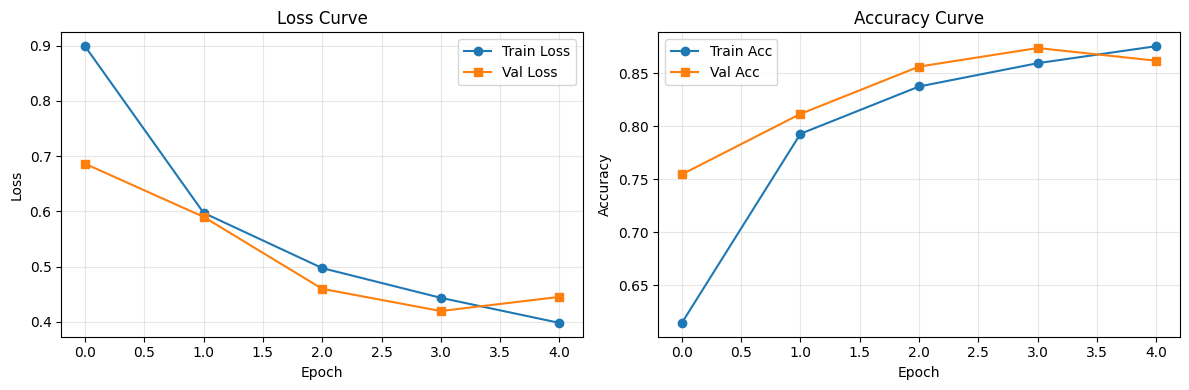

In [ ]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 4)
)

axes[0].plot(
    history['train_loss'],
    label='Train Loss',
    marker='o'
)

axes[0].plot(
    history['val_loss'],
    label='Val Loss',
    marker='s'
)

axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].set_title('Loss Curve')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    history['train_acc'],
    label='Train Acc',
    marker='o'
)

axes[1].plot(
    history['val_acc'],
    label='Val Acc',
    marker='s'
)

axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].set_title('Accuracy Curve')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 10. Матрица ошибок и classification report

In [ ]:
val_loss, val_acc, all_preds, all_labels = evaluate(
    model,
    test_loader,
    criterion
)

print(f"Test loss: {val_loss:.4f}")
print(f"Test accuracy: {val_acc:.4f}")

Evaluating: 100%|██████████| 119/119 [00:01<00:00, 115.11it/s]

Test loss: 0.4451
Test accuracy: 0.8618


In [ ]:
class_names = [
    'World',
    'Sports',
    'Business',
    'Sci/Tech'
]

print(
    classification_report(
        all_labels,
        all_preds,
        target_names=class_names
    )
)

              precision    recall  f1-score   support

       World       0.86      0.89      0.88      1900
      Sports       0.95      0.93      0.94      1900
    Business       0.89      0.72      0.80      1900
    Sci/Tech       0.77      0.90      0.83      1900

    accuracy                           0.86      7600
   macro avg       0.87      0.86      0.86      7600
weighted avg       0.87      0.86      0.86      7600



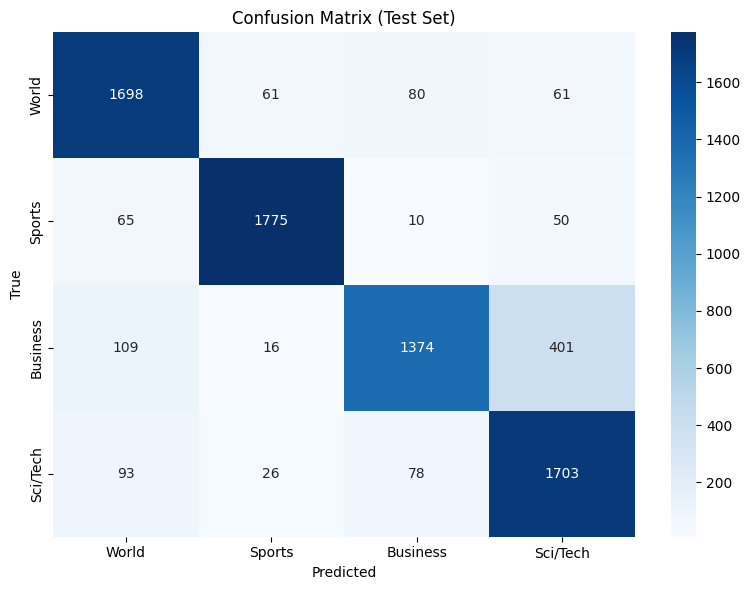

In [ ]:
cm = confusion_matrix(
    all_labels,
    all_preds
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix (Test Set)')
plt.tight_layout()
plt.show()

## 11. Контрольные вопросы для студентов

1. **Почему в этом ноутбуке используется `pack_padded_sequence`?**  
   Что произойдёт, если убрать `pack_padded_sequence` и просто подать `padded` тензор в RNN?

2. **Как `min_freq` влияет на размер словаря и на количество параметров embedding-слоя?**  
   Оцените, как меняется число обучаемых параметров при `MIN_FREQ = 2` и `MIN_FREQ = 10`.

3. **Что означает `lengths.cpu()` в вызове `pack_padded_sequence`?**  
   Почему длины должны быть на CPU, а не на GPU?

4. **Почему при `BIDIRECTIONAL = True` используется `torch.cat([hidden[-2], hidden[-1]], dim=1)`?**  
   Что хранится в `hidden[-2]` и `hidden[-1]`?

5. **Как размер `HIDDEN_DIM` связан с числом параметров RNN?**  
   Выведите формулу для числа параметров `nn.RNN` (без bias и с bias).

6. **Почему `clip_grad_norm_` особенно важен для RNN?**  
   С каким явлением он борется?

7. **Что произойдёт, если `MAX_LEN` сделать очень большим (например, 2048)?**  
   Как это повлияет на время обучения, память и качество?

8. **Почему `padding_idx=PAD_IDX` важен в `nn.Embedding`?**  
   Что произойдёт, если его не указывать?

9. **Как интерпретировать матрицу ошибок?**  
   Какие классы чаще всего путаются и почему?

10. **Почему accuracy может быть не лучшей метрикой для этой задачи?**  
    Посмотрите на `classification_report` и объясните, какие метрики здесь информативнее.

## 12. Домашнее задание

### Часть A. Эксперименты с гиперпараметрами

Проведите **минимум 5 экспериментов**, меняя по одному гиперпараметру за раз:

1. `MIN_FREQ`: 2, 5, 10
2. `MAX_LEN`: 128, 256, 512
3. `BATCH_SIZE`: 32, 64, 128
4. `EMBED_DIM` / `HIDDEN_DIM`: (64, 64), (128, 128), (256, 256)
5. `NUM_LAYERS`: 1, 2
6. `BIDIRECTIONAL`: True / False
7. `LEARNING_RATE`: 1e-3, 5e-4, 1e-4

Для каждого эксперимента зафиксируйте:
- размер словаря;
- число параметров модели;
- время одной эпохи;
- `val_loss` и `val_acc` после 3–5 эпох.

Сведите результаты в таблицу и постройте графики зависимости `val_acc` от каждого гиперпараметра.

### Часть B. Анализ ошибок

1. Найдите **10 примеров**, на которых модель ошибается.
2. Для каждого примера укажите: истинный класс, предсказанный класс, текст (можно первые 200 символов).
3. Предложите **гипотезы**, почему модель ошибается (короткий текст, смешанная тематика, редкие слова и т.д.).
4. Предложите **2–3 идеи**, как улучшить модель именно на этих примерах.

### Часть C. Улучшение архитектуры

Замените `nn.RNN` на одну из архитектур:
- `nn.LSTM`
- `nn.GRU`
- двунаправленный LSTM/GRU

Сравните с базовой RNN по тем же метрикам. Объясните, почему LSTM/GRU часто работают лучше на длинных последовательностях.

### Часть D. Мини-исследование

Проверьте гипотезу: **«чем длиннее текст, тем лучше модель его классифицирует»**.

1. Разбейте тестовые примеры на группы по длине (например, 0–50, 51–100, 101–200, 200+ слов).
2. Посчитайте accuracy для каждой группы.
3. Постройте график зависимости accuracy от длины.
4. Сформулируйте вывод: подтверждается ли гипотеза?

### Формат сдачи

- Ноутбук `.ipynb` со всеми выполненными ячейками.
- Краткий отчёт (markdown внутри ноутбука): таблица экспериментов, графики, анализ ошибок, выводы.
- Ссылка на GitHub / Colab или сам файл.

### Часть A. Графики val_acc от гиперпараметров

Ниже графики по уже проведённым экспериментам (один параметр за раз относительно baseline). Раздел 9 показывает кривые одного запуска по эпохам; эти графики сравнивают финальный val_acc между запусками.

Примечание: E5 (BATCH_SIZE=32) был запущен с MAX_LEN=512. Для AG_News это почти не влияет на метрики.

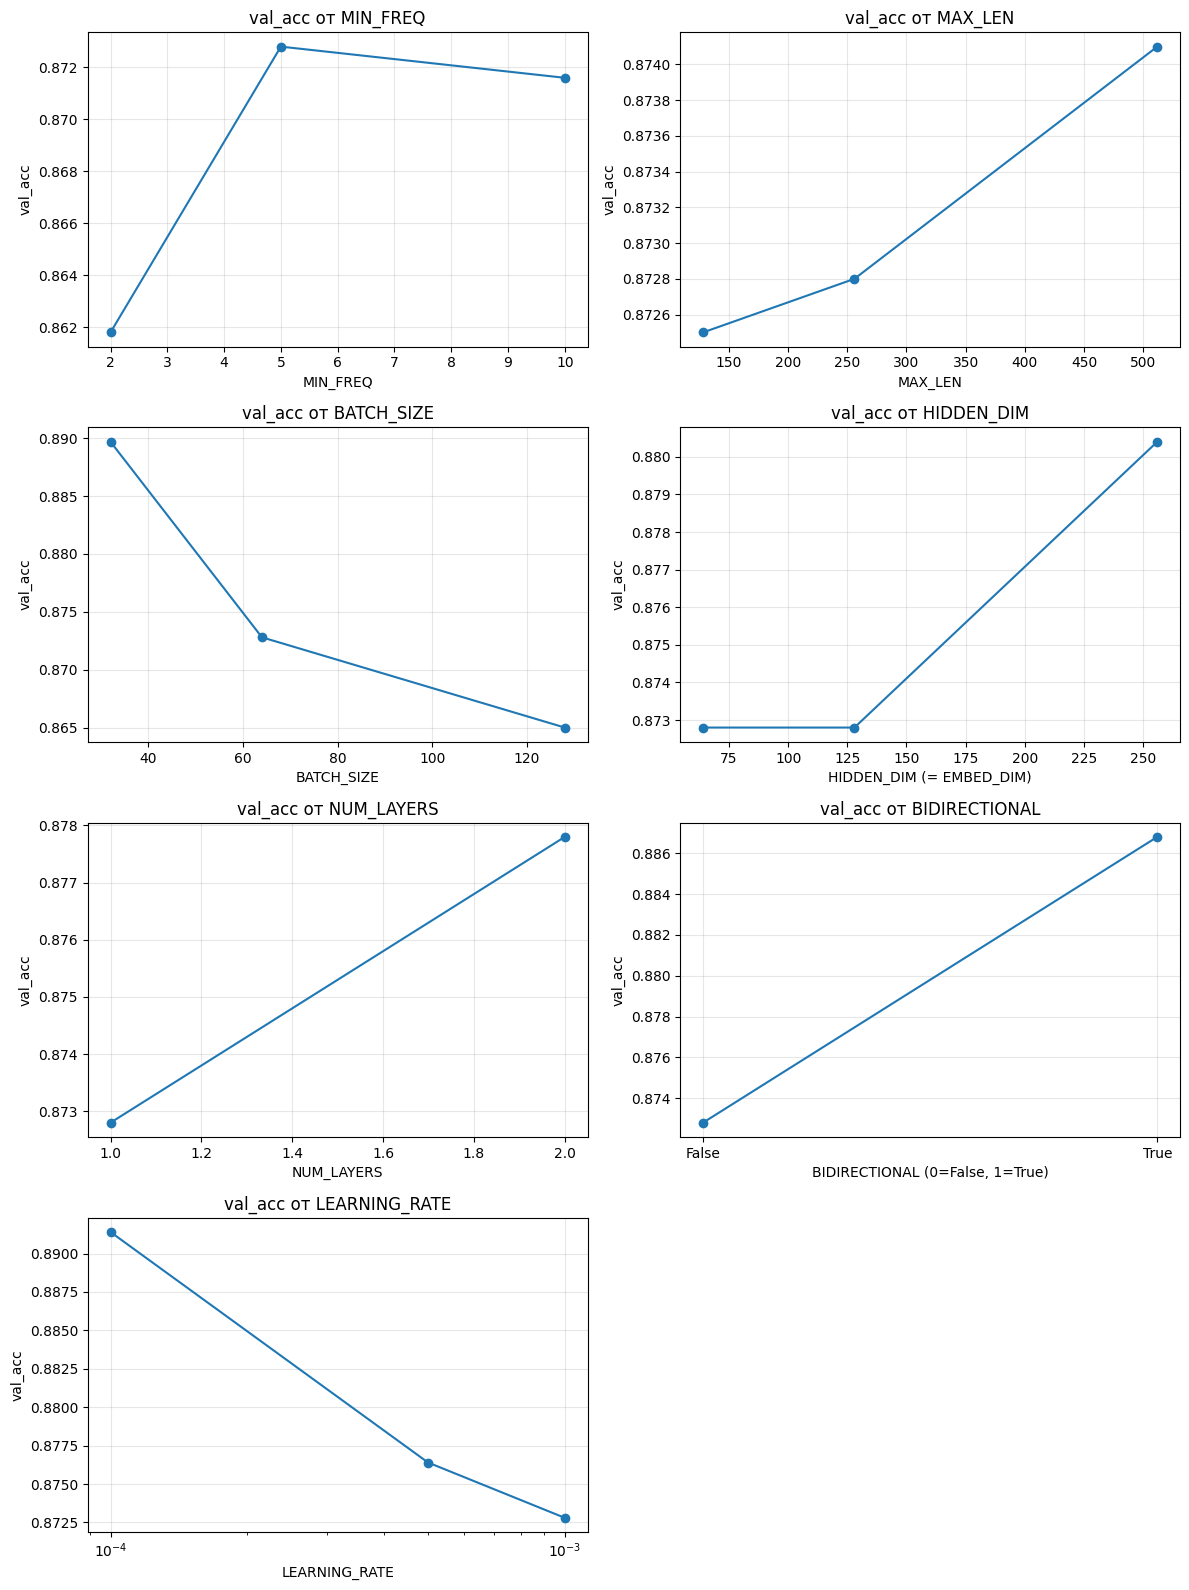

In [ ]:
# Результаты Части A: финальный val_acc после 5 эпох
results = {
    'MIN_FREQ': {
        'x': [2, 5, 10],
        'y': [0.8618, 0.8728, 0.8716],
        'xlabel': 'MIN_FREQ',
        'logx': False,
    },
    'MAX_LEN': {
        'x': [128, 256, 512],
        'y': [0.8725, 0.8728, 0.8741],
        'xlabel': 'MAX_LEN',
        'logx': False,
    },
    'BATCH_SIZE': {
        'x': [32, 64, 128],
        'y': [0.8897, 0.8728, 0.8650],
        'xlabel': 'BATCH_SIZE',
        'logx': False,
    },
    'HIDDEN_DIM': {
        'x': [64, 128, 256],
        'y': [0.8728, 0.8728, 0.8804],
        'xlabel': 'HIDDEN_DIM (= EMBED_DIM)',
        'logx': False,
    },
    'NUM_LAYERS': {
        'x': [1, 2],
        'y': [0.8728, 0.8778],
        'xlabel': 'NUM_LAYERS',
        'logx': False,
    },
    'BIDIRECTIONAL': {
        'x': [0, 1],
        'y': [0.8728, 0.8868],
        'xlabel': 'BIDIRECTIONAL (0=False, 1=True)',
        'logx': False,
        'xticks': ([0, 1], ['False', 'True']),
    },
    'LEARNING_RATE': {
        'x': [1e-3, 5e-4, 1e-4],
        'y': [0.8728, 0.8764, 0.8914],
        'xlabel': 'LEARNING_RATE',
        'logx': True,
    },
}

fig, axes = plt.subplots(4, 2, figsize=(12, 16))
axes = axes.ravel()

for i, (name, data) in enumerate(results.items()):
    ax = axes[i]
    ax.plot(data['x'], data['y'], marker='o')
    ax.set_xlabel(data['xlabel'])
    ax.set_ylabel('val_acc')
    ax.set_title(f'val_acc от {name}')
    ax.grid(alpha=0.3)
    if data['logx']:
        ax.set_xscale('log')
    xticks = data.get('xticks')
    if xticks is not None:
        ax.set_xticks(xticks[0])
        ax.set_xticklabels(xticks[1])

axes[-1].axis('off')
plt.tight_layout()
plt.show()

### Часть B. Анализ ошибок

Ячейка ниже берёт текущую обученную модель и печатает 10 случайных ошибок на тесте (фиксированный seed). Разбор примеров, гипотезы и идеи улучшения приведены в разделе 13. Отчёт.


In [ ]:
# Часть B: 10 ошибок модели на тесте
class_names = [
    'World',
    'Sports',
    'Business',
    'Sci/Tech'
]

_, _, all_preds, all_labels = evaluate(
    model,
    test_loader,
    criterion
)

error_indices = [
    i for i, (y, p) in enumerate(zip(all_labels, all_preds))
    if y != p
]

rng = np.random.default_rng(SEED)
n_show = min(10, len(error_indices))
chosen = rng.choice(error_indices, size=n_show, replace=False)
chosen = np.sort(chosen)

print(f"Всего ошибок на тесте: {len(error_indices)} из {len(all_labels)}")
print()

error_examples = []

for k, idx in enumerate(chosen, start=1):
    true_label, text = test_data[idx]
    pred_label = int(all_preds[idx])
    tokens = tokenizer(text)
    n_unk = sum(
        1 for token in tokens
        if vocab.get(token, UNK_IDX) == UNK_IDX
    )

    example = {
        'k': k,
        'idx': int(idx),
        'true': int(true_label),
        'pred': pred_label,
        'n_tokens': len(tokens),
        'n_unk': n_unk,
        'text': text,
    }
    error_examples.append(example)

    print(f"--- Пример {k} (idx={idx}) ---")
    print(
        f"Истинный класс:      {true_label} "
        f"({class_names[true_label]})"
    )
    print(
        f"Предсказанный класс: {pred_label} "
        f"({class_names[pred_label]})"
    )
    print(
        f"Длина (токенов): {len(tokens)}, "
        f"неизвестных токенов: {n_unk}"
    )
    print(f"Текст: {text[:200]}")
    print()

Разбор 10 ошибок и идеи улучшения приведены в разделе 13. Отчёт.


### Часть C. Улучшение архитектуры

Одно сравнение: `nn.RNN` заменён на двунаправленный `nn.LSTM`. Остальные гиперпараметры как у baseline (если словарь собран с другим MIN_FREQ, это нужно учесть при сравнении). После обучения смотрите блок `=== EXPERIMENT RESULT (LSTM) ===`. Почему LSTM лучше обычной RNN: раздел 13. Отчёт.


In [ ]:
class LSTMClassifier(nn.Module):
    def __init__(
        self,
        vocab_size,
        embed_dim,
        hidden_dim,
        num_classes,
        num_layers=1,
        dropout=0.2,
        bidirectional=True
    ):
        super().__init__()

        self.embedding = nn.Embedding(
            num_embeddings=vocab_size,
            embedding_dim=embed_dim,
            padding_idx=PAD_IDX
        )

        self.rnn = nn.LSTM(
            input_size=embed_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0,
            bidirectional=bidirectional
        )

        rnn_output_dim = (
            hidden_dim * 2
            if bidirectional
            else hidden_dim
        )

        self.fc = nn.Linear(
            rnn_output_dim,
            num_classes
        )
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, lengths):
        embedded = self.dropout(self.embedding(x))

        packed = pack_padded_sequence(
            embedded,
            lengths.cpu(),
            batch_first=True,
            enforce_sorted=False
        )

        # LSTM возвращает (h_n, c_n); для классификации берём h_n
        _, (hidden, _) = self.rnn(packed)

        if self.rnn.bidirectional:
            last_hidden = torch.cat(
                [hidden[-2], hidden[-1]],
                dim=1
            )
        else:
            last_hidden = hidden[-1]

        return self.fc(self.dropout(last_hidden))

In [ ]:
# Часть C: гиперпараметры как у baseline E0, архитектура bidirectional LSTM
EMBED_DIM = 128
HIDDEN_DIM = 128
NUM_LAYERS = 1
DROPOUT = 0.2
LEARNING_RATE = 1e-3
NUM_EPOCHS = 5
LSTM_BIDIRECTIONAL = True

lstm_model = LSTMClassifier(
    vocab_size=len(vocab),
    embed_dim=EMBED_DIM,
    hidden_dim=HIDDEN_DIM,
    num_classes=4,
    num_layers=NUM_LAYERS,
    dropout=DROPOUT,
    bidirectional=LSTM_BIDIRECTIONAL
).to(device)

lstm_n_params = sum(
    p.numel() for p in lstm_model.parameters() if p.requires_grad
)
print(lstm_model)
print(f"Количество обучаемых параметров: {lstm_n_params:,}")

lstm_criterion = nn.CrossEntropyLoss()
lstm_optimizer = optim.Adam(
    lstm_model.parameters(),
    lr=LEARNING_RATE
)

lstm_history = {
    'train_loss': [],
    'train_acc': [],
    'val_loss': [],
    'val_acc': [],
    'epoch_time': []
}

for epoch in range(NUM_EPOCHS):
    start = time.time()
    train_loss, train_acc = train_epoch(
        lstm_model,
        train_loader,
        lstm_optimizer,
        lstm_criterion
    )
    epoch_time = time.time() - start

    val_loss, val_acc, _, _ = evaluate(
        lstm_model,
        test_loader,
        lstm_criterion
    )

    lstm_history['train_loss'].append(train_loss)
    lstm_history['train_acc'].append(train_acc)
    lstm_history['val_loss'].append(val_loss)
    lstm_history['val_acc'].append(val_acc)
    lstm_history['epoch_time'].append(epoch_time)

    print(
        f"Epoch {epoch + 1}/{NUM_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f} | "
        f"Time: {epoch_time:.1f}s"
    )

In [ ]:
mean_epoch_time = (
    sum(lstm_history['epoch_time']) / len(lstm_history['epoch_time'])
)

print("=== EXPERIMENT RESULT (LSTM) ===")
print(f"MIN_FREQ={MIN_FREQ}  MAX_LEN={MAX_LEN}  BATCH_SIZE={BATCH_SIZE}")
print(f"EMBED_DIM={EMBED_DIM}  HIDDEN_DIM={HIDDEN_DIM}  NUM_LAYERS={NUM_LAYERS}")
print(f"BIDIRECTIONAL={LSTM_BIDIRECTIONAL}  LEARNING_RATE={LEARNING_RATE}")
print("rnn_type=LSTM")
print(f"vocab_size={len(vocab)}")
print(f"n_params={lstm_n_params}")
print(f"mean_epoch_time={mean_epoch_time:.1f}s")
print(f"last_val_loss={lstm_history['val_loss'][-1]:.4f}")
print(f"last_val_acc={lstm_history['val_acc'][-1]:.4f}")

### Часть D. Мини-исследование: зависит ли accuracy от длины текста

Гипотеза: чем длиннее текст, тем лучше модель его классифицирует.

Ячейка ниже считает длину в токенах (тот же tokenizer, что в модели), бьёт тест на группы 0-50, 51-100, 101-200, 200+ и считает accuracy в каждой группе. Если есть `lstm_model` из Части C, используется он, иначе текущий `model`.

Вывод по гипотезе: раздел 13. Отчёт.


In [ ]:
# Часть D: accuracy по длине текста
part_d_model = lstm_model if 'lstm_model' in dir() else model
part_d_crit = lstm_criterion if 'lstm_criterion' in dir() else criterion
model_name = 'LSTM' if 'lstm_model' in dir() else 'RNN'
print(f"Модель для Части D: {model_name}")

_, overall_acc, d_preds, d_labels = evaluate(
    part_d_model,
    test_loader,
    part_d_crit
)
print(f"Accuracy на всём тесте: {overall_acc:.4f}")
print()

bins = [
    ('0-50', 0, 50),
    ('51-100', 51, 100),
    ('101-200', 101, 200),
    ('200+', 201, 10 ** 9),
]

lengths = [len(tokenizer(text)) for _, text in test_data]

print(f"{'Группа':<12} {'N':>6} {'accuracy':>10}")
group_names = []
group_acc = []
group_n = []

for name, lo, hi in bins:
    idx = [
        i for i, L in enumerate(lengths)
        if lo <= L <= hi
    ]
    n = len(idx)
    if n == 0:
        acc = float('nan')
    else:
        correct = sum(
            1 for i in idx if d_preds[i] == d_labels[i]
        )
        acc = correct / n
    group_names.append(name)
    group_acc.append(acc)
    group_n.append(n)
    acc_str = f"{acc:.4f}" if n else "n/a"
    print(f"{name:<12} {n:>6} {acc_str:>10}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(group_names, group_acc)
ax.set_ylim(0, 1)
ax.set_xlabel('Длина текста (токены)')
ax.set_ylabel('accuracy')
ax.set_title(f'Accuracy от длины текста ({model_name})')
ax.grid(axis='y', alpha=0.3)
for x, acc, n in zip(group_names, group_acc, group_n):
    if n > 0:
        ax.text(x, acc + 0.02, f'{acc:.3f}\nn={n}', ha='center')
plt.tight_layout()
plt.show()

## 13. Отчёт

Письменная часть домашнего задания: использование ИИ, ответы на контрольные вопросы, таблица экспериментов, анализ ошибок, LSTM и исследование длины текста.

### Использование ИИ

ИИ использовался как помощник при оформлении отчёта и кода. Запуски обучения, выбор значений гиперпараметров и проверка вывода ячеек выполнялись самостоятельно.

**Ведение таблицы экспериментов.** ИИ помогал заносить результаты запусков в таблицу и держать план «один параметр за раз».

Примеры промптов:
- добавь результат ... в таблицу;
- составь пошаговый план эксперимента;
- какой параметр меняем дальше?

**Написание кода.** ИИ писал вспомогательные ячейки, которые не заменяют исходный tutorial, а добавляют измерения и части B/C/D.

- код для исследования влияния MAX_LEN (форма батча, реальные длины, доля паддинга);
- код для ведения статистики эксперимента (время эпохи, сводка vocab / n_params / val_loss / val_acc);
- код для смены архитектуры (двунаправленный LSTM вместо RNN);
- код для отрисовки графиков val_acc от гиперпараметров и accuracy от длины текста.

**Дополнительно (тоже с помощью ИИ):**
- пояснения к гиперпараметрам и архитектуре (эпоха, learning rate, однонаправленная и двунаправленная RNN, вентили LSTM);

### Контрольные вопросы (раздел 11)

**1. Почему используется `pack_padded_sequence`?**

(Паддинг — это искусственное дополнение короткого текста «пустыми» токенами, чтобы в одном батче все примеры стали одной длины) В батче тексты разной длины, pad_sequence дополняет их до длины самого длинного. Если подать такой тензор в RNN как есть, модель будет обрабатывать паддинг как обычные токены: портится hidden state и зря считаются шаги.

pack_padded_sequence вместе с lengths говорит RNN, где кончается реальный текст. На паддинге RNN не делает шагов. Если убрать packing, качество обычно падает, обучение чуть замедляется, а на коротких текстах в длинном батче скрытое состояние сильнее «зашумляется» паддингом.

**2. Как `min_freq` влияет на словарь и параметры embedding?**

MIN_FREQ отвечат за попадание слова в словать на основе того, сколько раз оно встретилось. Сравним значение 2 и 10: словарь и embedding почти вдвое меньше при 10, потому что выкинуты все слова с частотой 2–9.

**3. Что означает `lengths.cpu()`?**

pack_padded_sequence ожидает тензор длин на CPU, даже если батч лежит на GPU. Это требование реализации в PyTorch: длины нужны, чтобы на CPU собрать packed-структуру, а не для матричных операций на GPU. Если оставить длины на CUDA, будет ошибка или предупреждение.

**4. Почему при `BIDIRECTIONAL = True` делают `torch.cat([hidden[-2], hidden[-1]], dim=1)`?**

- hidden[-2] — финальное состояние forward (после последнего слова)
- hidden[-1] — финальное состояние backward (после первого слова при чтении с конца)

Их склеивают в вектор длины 2 * HIDDEN_DIM, и его берёт линейный слой. Если взять только hidden[-1], классификатор увидит лишь одно направление.

**5. Как `HIDDEN_DIM` связан с числом параметров RNN?**

Для одного слоя nn.RNN, input size I, hidden size H:

- без bias: `H*I + H*H`
- с bias: `H*I + H*H + 2H` (bias для input-to-hidden и hidden-to-hidden)

Для следующих слоёв I заменяется на H (или на 2H, если предыдущий слой двунаправленный). Двунаправленная RNN удваивает параметры RNN-блока: два независимых направления. Embedding при этом не зависит от H, только от V и EMBED_DIM; Linear зависит: num_classes * H или num_classes * 2H.

Пример baseline: H = I = 128, 1 слой, не bidirectional: RNN = 128*128 + 128*128 + 256 = 33024.

**6. Почему важен `clip_grad_norm_`?**

Он ограничивает суммарную норму градиентов (`max_norm=1.0` в этом ноутбуке). У RNN градиент идёт через много шагов по времени. Если множители больше 1, норма может взорваться (exploding gradient): слишком большой шаг, NaN, расходящийся loss. Клип не лечит затухание градиента, он борется именно со взрывом.

**7. Что будет при `MAX_LEN = 2048`?**

На AG_News почти ничего полезного: типичная длина около 30-60 токенов, в диагностике батча max был 94. Обрезать нечего, качество не вырастет. Зато в худшем случае тензор батча станет очень широким, вырастут память и время (RNN линейна по длине). На корпусе с длинными документами память и время вырастут заметно, а обычная RNN всё равно слабо использует дальний контекст (затухание градиента). Имеет смысл LSTM/GRU и packing, а не бесконечный MAX_LEN.

**8. Зачем `padding_idx=PAD_IDX` в `nn.Embedding`?**

Строка embedding для `<pad>` фиксируется нулями, и градиент на неё не идёт. Паддинг не становится «ещё одним словом». Если индекс не указать, модель будет учить вектор паддинга; на него попадут все выровненные позиции, и RNN (без packing) начнёт видеть паддинг как осмысленный токен.

**9. Как читать матрицу ошибок?**

Строки — истинный класс, столбцы — предсказание. Диагональ: верные ответы. Вне диагонали: типичные путаницы.

По classification_report этой модели (accuracy 0.86, 1900 примеров на класс):

- Sports лучше всех (precision 0.95, recall 0.93, f1 0.94): спортивная лексика довольно отдельная;
- World: f1 0.88;
- Sci/Tech: precision 0.77, recall 0.90, f1 0.83;
- Business хуже всех по recall (0.72) и f1 (0.80).

Чаще всего путаются Business и Sci/Tech: новости про IT-сделки, выручку software-компаний, телеком. Это же видно в Части B (8 из 10 разобранных ошибок). World путается с Business, когда в финансовой новости много геополитики (Saddam, Беларусь, скандал Clinton-Lewinsky).

**10. Почему accuracy может быть не лучшей метрикой?**

Здесь классы сбалансированы (по 1900 в тесте), поэтому accuracy = 0.86 не врёт про долю верных ответов. Но она не показывает, *какой* класс ломается. Precision / recall / f1 по классам информативнее: Business пропускается (низкий recall), Sci/Tech часто назначается чужим Business-примерам (ниже precision). Для отладки модели смотрят classification_report и матрицу ошибок, а не одну цифру accuracy.

### Часть A. Таблица экспериментов

Датасет AG_News, 4 класса. Базовая RNN: MIN_FREQ=5, MAX_LEN=256, BATCH_SIZE=64, EMBED=HIDDEN=128, NUM_LAYERS=1, BIDIRECTIONAL=False, LR=1e-3, 5 эпох. Менялся один параметр за раз. val_loss и val_acc после 5-й эпохи. Время эпохи — среднее по train.

| ID | Что меняем | MIN_FREQ | MAX_LEN | BATCH | EMBED | HIDDEN | LAYERS | BIDIR | LR | Словарь | Параметры | Время, с | val_loss | val_acc |
|----|-----------|----------|---------|-------|-------|--------|--------|-------|------|---------|-----------|----------|----------|---------|
| E0 | baseline | 5 | 256 | 64 | 128 | 128 | 1 | False | 1e-3 | 27831 | 3595908 | 25.1 | 0.4342 | 0.8728 |
| E1 | MIN_FREQ | 2 | 256 | 64 | 128 | 128 | 1 | False | 1e-3 | 44138 | 5683204 | 27.5 | 0.4451 | 0.8618 |
| E2 | MIN_FREQ | 10 | 256 | 64 | 128 | 128 | 1 | False | 1e-3 | 19638 | 2547204 | 24.8 | 0.4370 | 0.8716 |
| E3 | MAX_LEN | 5 | 128 | 64 | 128 | 128 | 1 | False | 1e-3 | 27831 | 3595908 | 24.3 | 0.4263 | 0.8725 |
| E4 | MAX_LEN | 5 | 512 | 64 | 128 | 128 | 1 | False | 1e-3 | 27831 | 3595908 | 25.0 | 0.4262 | 0.8741 |
| E5 | BATCH_SIZE | 5 | 256 | 32 | 128 | 128 | 1 | False | 1e-3 | 27831 | 3595908 | 44.7 | 0.3571 | 0.8897 |
| E6 | BATCH_SIZE | 5 | 256 | 128 | 128 | 128 | 1 | False | 1e-3 | 27831 | 3595908 | 15.9 | 0.4727 | 0.8650 |
| E7 | EMBED/HIDDEN | 5 | 256 | 64 | 64 | 64 | 1 | False | 1e-3 | 27831 | 1789764 | 25.1 | 0.4349 | 0.8728 |
| E8 | EMBED/HIDDEN | 5 | 256 | 64 | 256 | 256 | 1 | False | 1e-3 | 27831 | 7257348 | 29.4 | 0.3940 | 0.8804 |
| E9 | NUM_LAYERS | 5 | 256 | 64 | 128 | 128 | 2 | False | 1e-3 | 27831 | 3628932 | 34.2 | 0.3972 | 0.8778 |
| E10 | BIDIRECTIONAL | 5 | 256 | 64 | 128 | 128 | 1 | True | 1e-3 | 27831 | 3629444 | 33.6 | 0.3290 | 0.8868 |
| E11 | LEARNING_RATE | 5 | 256 | 64 | 128 | 128 | 1 | False | 5e-4 | 27831 | 3595908 | 25.7 | 0.4074 | 0.8764 |
| E12 | LEARNING_RATE | 5 | 256 | 64 | 128 | 128 | 1 | False | 1e-4 | 27831 | 3595908 | 26.0 | 0.3955 | 0.8914 |
| C1 | LSTM bidir | 2 | 256 | 64 | 128 | 128 | 1 | True | 1e-3 | 44138 | 5914884 | 39.2 | 0.2601 | 0.9208 |

Примечания:
- словарь зависит только от MIN_FREQ;
- E5 фактически шёл с MAX_LEN=512, на AG_News это почти не влияет;
- C1 сравнивать честно с E1 (оба MIN_FREQ=2), а не с E0.

**MIN_FREQ.** При 2 словарь 44138 и val_acc 0.8618 (хуже). При 10 словарь 19638 и 0.8716, почти как baseline 0.8728. Редкие слова раздувают embedding и мешают.

**MAX_LEN.** 128 / 256 / 512 дают почти одну точность. Тексты короткие (диагностика батча: max около 94, mean около 46), обрезать нечего.

**BATCH_SIZE.** 32: лучший val_acc среди RNN с MIN_FREQ=5 (0.8897), но 44.7 с на эпоху. 128: быстрее (15.9 с) и хуже (0.8650).

**EMBED/HIDDEN.** 64/64 совпал с 128/128 по accuracy. 256/256 чуть лучше (0.8804) ценой 7.3 млн параметров.

**NUM_LAYERS и BIDIR.** Два слоя: 0.8778 и 34 с. Двунаправленная RNN: 0.8868, val_loss 0.329, 33.6 с.

**LEARNING_RATE.** Меньший шаг лучше за 5 эпох: 1e-4 дал 0.8914. Время почти не меняется.

Сильнее всего на RNN влияли BATCH_SIZE, LEARNING_RATE и BIDIRECTIONAL. Слабее всего MAX_LEN.

### Задание 1. Словарь и редкие слова

MIN_FREQ: токен идёт в словарь, только если встретился не меньше порога раз, иначе станет `<unk>`. PAD_IDX=0 и UNK_IDX=1 от порога не зависят.

Редкие слова помогают, если несут сильный сигнал (термин, яркая оценка). Мешают, если это шум и опечатки: строка embedding учится на 2-3 примерах, растут параметры и переобучение. MIN_FREQ работает как регуляризатор. Эксперименты это подтвердили: MIN_FREQ=2 хуже и тяжелее, 5 и 10 близки по качеству.

### Часть B. Анализ ошибок

8 из 10 ошибок: Business против Sci/Tech. Длина обычная, `<unk>` почти нет. Путается отрасль компании и тип события.

1. idx=549. Business → Sci/Tech. Virgin / телеком / cell phone. Сделка, но слова про связь.
2. idx=568. Sci/Tech → Business. Microsoft-Time Warner buy / acquire. Метка про DRM, текст про сделку.
3. idx=600. Business → World. Банк в Беларуси, но Saddam Hussein / US.
4. idx=1364. Sci/Tech → Business. Hyundai signs deal for truck plant.
5. idx=3101. Business → Sci/Tech. Прогноз выручки PeopleSoft плюс HTML Reuters.
6. idx=3135. Business → Sci/Tech. Суд по Visa/MasterCard, битый `#39;`.
7. idx=4888. Sci/Tech → Business. Климат / Arctic Council / nations.
8. idx=5280. Business → Sci/Tech. IPO и start-ups.
9. idx=5828. Business → World. Назначение в NYT и Clinton-Lewinsky.
10. idx=6427. Business → Sci/Tech. Software-компания и ёлки, слово software сильнее.

Идеи: двунаправленный LSTM/GRU; почистить HTML и `#39;`; отдельно отличать IT-компанию от финансового события.

### Часть C. LSTM

Обычная RNN перезаписывает hidden почти целиком, на длинной последовательности градиент затухает. LSTM держит ячейку памяти и вентили (forget / input / output), сигнал из начала текста доходит лучше. Двунаправленный LSTM видит заголовок и конец новости.

| Модель | MIN_FREQ | Параметры | Время, с | val_loss | val_acc |
|---|---|---|---|---|---|
| E1, RNN | 2 | 5683204 | 27.5 | 0.4451 | 0.8618 |
| C1, LSTM bidir | 2 | 5914884 | 39.2 | 0.2601 | 0.9208 |
| E0, RNN baseline | 5 | 3595908 | 25.1 | 0.4342 | 0.8728 |

Честное сравнение: C1 vs E1. LSTM: +0.059 accuracy, loss почти вдвое ниже, эпоха дольше. Гипотеза, что LSTM лучше RNN, подтверждается.

### Часть D. Accuracy и длина текста

Гипотеза: чем длиннее текст, тем лучше классификация. Модель: RNN, accuracy на тесте 0.8618 (как E1).

| Группа | N | accuracy |
|---|---|---|
| 0-50 | 5240 | 0.8616 |
| 51-100 | 2242 | 0.8608 |
| 101-200 | 115 | 0.8870 |
| 200+ | 3 | 1.0000 |

Гипотеза не подтверждается. Почти все новости короткие, у двух больших групп accuracy одинаковая. 101-200 это 115 примеров, 200+ это 3 примера. Это согласуется с тем, что MAX_LEN почти не влиял.
